## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов.

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК.

После жесткого дедлайна работы не принимаются.

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [15]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

In [16]:
# a) Онлайн-мониторинг: 1 (3σ с rolling-окном), 4 (CUSUM), 5 (EWMA)
# b) Батч-анализ по историческим данным: 2 (Generalized ESD), 3 (Grubbs test), 6 (STL + Generalized ESD)
print("a) 1, 4, 5")
print("b) 2, 3, 6")

a) 1, 4, 5
b) 2, 3, 6


### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [17]:
df = pd.read_csv('hw_4_fmcg.csv')

In [18]:
df['date'] = pd.to_datetime(df['date'])

In [19]:
df.head()

,date,items_sold,gmv,avg_item_price
0,2023-01-01,2907,14944.41,5.140836
1,2023-01-02,3030,16065.13,5.302023
2,2023-01-03,3070,17170.30,5.592932
3,2023-01-04,2708,14367.19,5.305462
4,2023-01-05,3177,16918.53,5.325316


Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

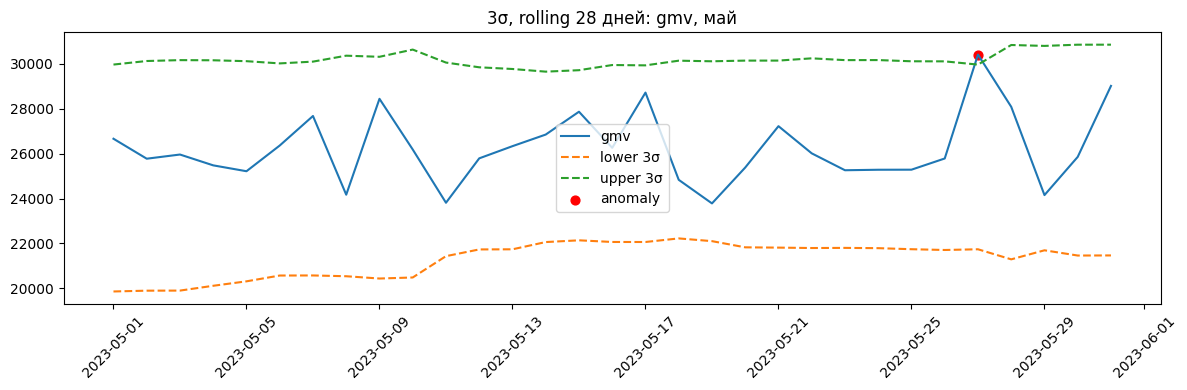

gmv аномалии за май: ['2023-05-27']


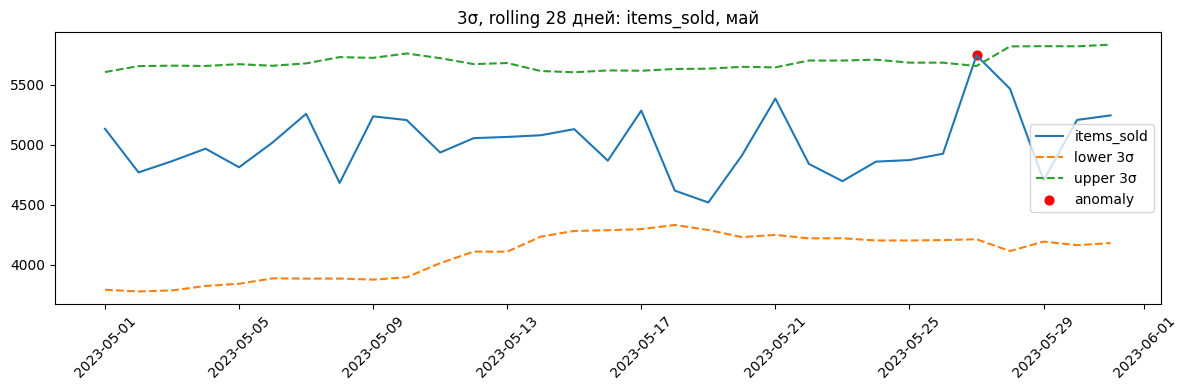

items_sold аномалии за май: ['2023-05-27']


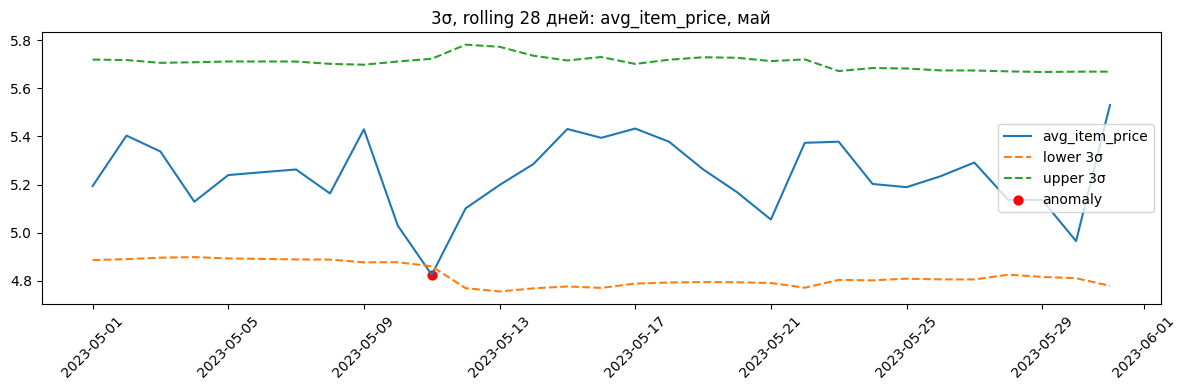

avg_item_price аномалии за май: ['2023-05-11']


In [20]:
def rule_3sigma(series, window=28, k=3):
    s = pd.Series(series).astype(float)
    mean = s.rolling(window).mean().shift(1)
    std = s.rolling(window).std().shift(1)
    lower = mean - k * std
    upper = mean + k * std
    anomaly = (s < lower) | (s > upper)
    return pd.DataFrame({'value': s, 'mean': mean, 'std': std,
                         'lower': lower, 'upper': upper, 'anomaly': anomaly})

metrics = ['gmv', 'items_sold', 'avg_item_price']
may_mask = (df['date'].dt.year == 2023) & (df['date'].dt.month == 5)

sigma_res = {}
for m in metrics:
    sigma_res[m] = rule_3sigma(df[m])
    plot_df = df.loc[may_mask, ['date']].copy()
    plot_df['value'] = sigma_res[m].loc[may_mask, 'value'].values
    plot_df['lower'] = sigma_res[m].loc[may_mask, 'lower'].values
    plot_df['upper'] = sigma_res[m].loc[may_mask, 'upper'].values
    plot_df['anomaly'] = sigma_res[m].loc[may_mask, 'anomaly'].values

    plt.figure(figsize=(12, 4))
    plt.plot(plot_df['date'], plot_df['value'], label=m)
    plt.plot(plot_df['date'], plot_df['lower'], '--', label='lower 3σ')
    plt.plot(plot_df['date'], plot_df['upper'], '--', label='upper 3σ')
    an = plot_df[plot_df['anomaly']]
    plt.scatter(an['date'], an['value'], color='red', s=40, label='anomaly')
    plt.title(f'3σ, rolling 28 дней: {m}, май')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(m, 'аномалии за май:', an['date'].dt.strftime('%Y-%m-%d').tolist())

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

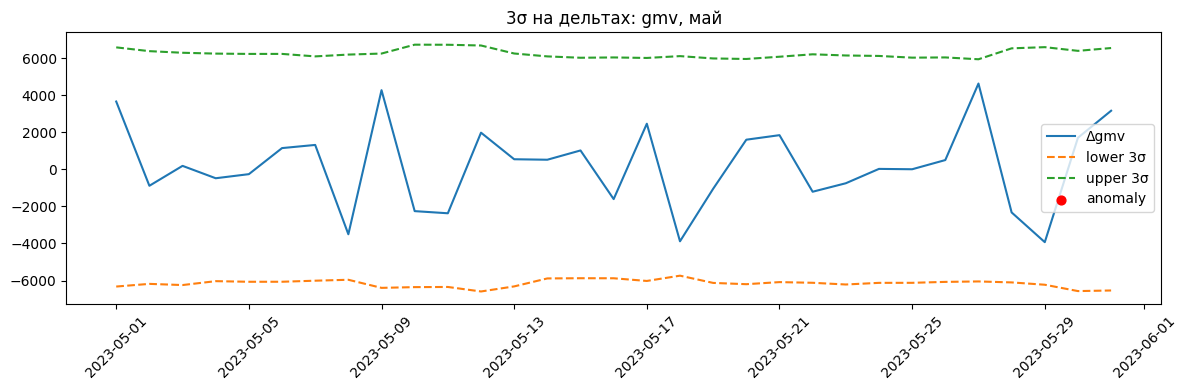

gmv аномалии дельт за май: []


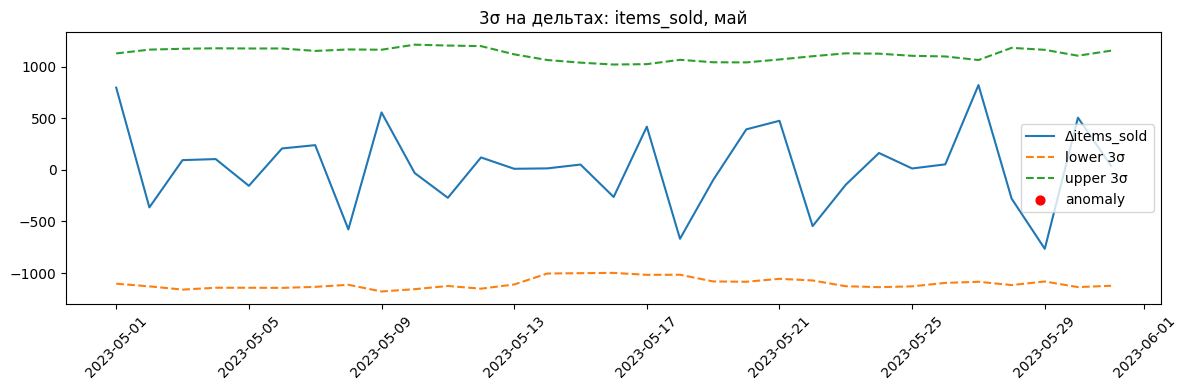

items_sold аномалии дельт за май: []


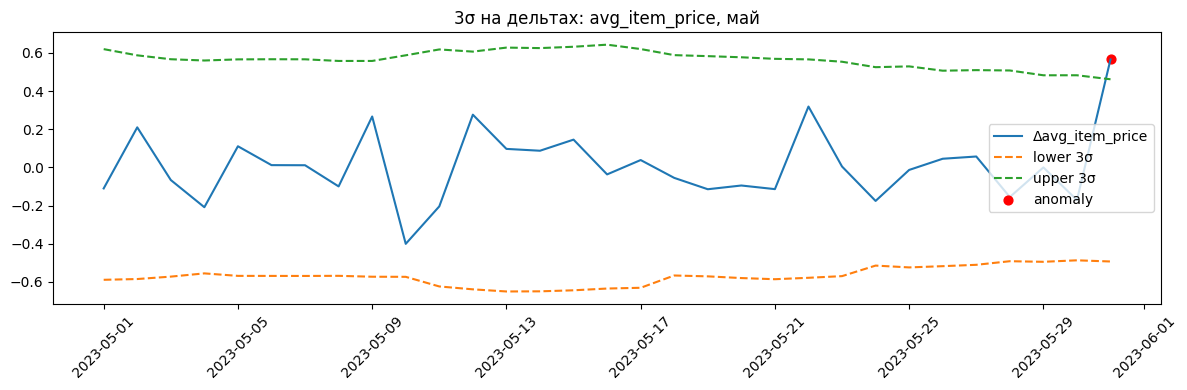

avg_item_price аномалии дельт за май: ['2023-05-31']


In [21]:
delta_res = {}

for m in metrics:
    delta = df[m].diff()
    delta_res[m] = rule_3sigma(delta)

    plot_df = df.loc[may_mask, ['date']].copy()
    plot_df['value'] = delta_res[m].loc[may_mask, 'value'].values
    plot_df['lower'] = delta_res[m].loc[may_mask, 'lower'].values
    plot_df['upper'] = delta_res[m].loc[may_mask, 'upper'].values
    plot_df['anomaly'] = delta_res[m].loc[may_mask, 'anomaly'].values

    plt.figure(figsize=(12, 4))
    plt.plot(plot_df['date'], plot_df['value'], label=f'Δ{m}')
    plt.plot(plot_df['date'], plot_df['lower'], '--', label='lower 3σ')
    plt.plot(plot_df['date'], plot_df['upper'], '--', label='upper 3σ')
    an = plot_df[plot_df['anomaly']]
    plt.scatter(an['date'], an['value'], color='red', s=40, label='anomaly')
    plt.title(f'3σ на дельтах: {m}, май')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(m, 'аномалии дельт за май:', an['date'].dt.strftime('%Y-%m-%d').tolist())

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [22]:
def generalized_esd(x, max_outliers=None, alpha=0.05):
    # ESD — батч-метод, максимум выбросов — 10% длины ряда

    x = np.asarray(x, dtype=float)
    valid = ~np.isnan(x)
    mask = np.zeros(len(x), dtype=bool)

    if valid.sum() < 3:
        return mask, []

    vals = x[valid]
    idx_valid = np.where(valid)[0]
    n = len(vals)

    if max_outliers is None:
        max_outliers = math.floor(0.1 * n)
    max_outliers = min(max_outliers, n - 2)

    remaining_vals = vals.copy()
    remaining_idx = idx_valid.copy()

    R = []
    removed = []

    for i in range(1, max_outliers + 1):
        mean = remaining_vals.mean()
        std = remaining_vals.std(ddof=1)
        if std == 0:
            break
        dev = np.abs(remaining_vals - mean)
        j = np.argmax(dev)
        R.append(dev[j] / std)
        removed.append(remaining_idx[j])
        remaining_vals = np.delete(remaining_vals, j)
        remaining_idx = np.delete(remaining_idx, j)

    if not R:
        return mask, []

    R = np.array(R)
    crit = []
    for i in range(1, len(R) + 1):
        df_t = n - i - 1
        if df_t <= 0:
            crit.append(np.nan)
            continue
        p = 1 - alpha / (2 * (n - i + 1))
        t_val = t.ppf(p, df_t)
        lam = ((n - i) * t_val) / math.sqrt((n - i - 1 + t_val ** 2) * (n - i + 1))
        crit.append(lam)

    crit = np.array(crit)
    k = 0
    for i in range(len(R)):
        if R[i] > crit[i]:
            k = i + 1

    for pos in removed[:k]:
        mask[pos] = True
    return mask, removed[:k]


for m in metrics:
    delta = df[m].diff()
    x_may = delta[may_mask].values
    dates_may = df.loc[may_mask, 'date'].values

    esd_mask, _ = generalized_esd(x_may, alpha=0.05)
    esd_dates = set(pd.to_datetime(dates_may[esd_mask]).strftime('%Y-%m-%d'))
    sigma_dates = set(pd.to_datetime(
        dates_may[delta_res[m].loc[may_mask, 'anomaly'].values]
    ).strftime('%Y-%m-%d'))

    print(f'\n{m}')
    print('Generalized ESD:', sorted(esd_dates))
    print('3σ на дельтах:', sorted(sigma_dates))
    print('Только ESD:', sorted(esd_dates - sigma_dates))
    print('Только 3σ:', sorted(sigma_dates - esd_dates))
    print('Совпали:', sorted(esd_dates & sigma_dates))


gmv
Generalized ESD: []
3σ на дельтах: []
Только ESD: []
Только 3σ: []
Совпали: []

items_sold
Generalized ESD: []
3σ на дельтах: []
Только ESD: []
Только 3σ: []
Совпали: []

avg_item_price
Generalized ESD: ['2023-05-31']
3σ на дельтах: ['2023-05-31']
Только ESD: []
Только 3σ: []
Совпали: ['2023-05-31']


Вывод по сравнению Generalized ESD и 3σ: методы не разошлись.

#### 5. STL-разложение — 2 балла

1) Для каждой метрики выполните STL-разложение с недельной сезонностью (7 дней) на данных всего датасета:
- gmv;
- items_sold;
- avg_item_price.

Используйте STL из библиотеки statsmodels (уже есть в импортах).
  
2) Для каждой метрики визуализируйте компоненты: тренд, сезонность, остатки (на всем датасете).

4) На остатках примените Generalized ESD, можете использовать функцию из прошлого шага. Это упражнение проделываем только на данных ЗА МАЙ.

5) Подумайте, для каждой ли метрики имеет смысл использовать STL, везде ли визуально присутствуют тренд и недельная сезонность?

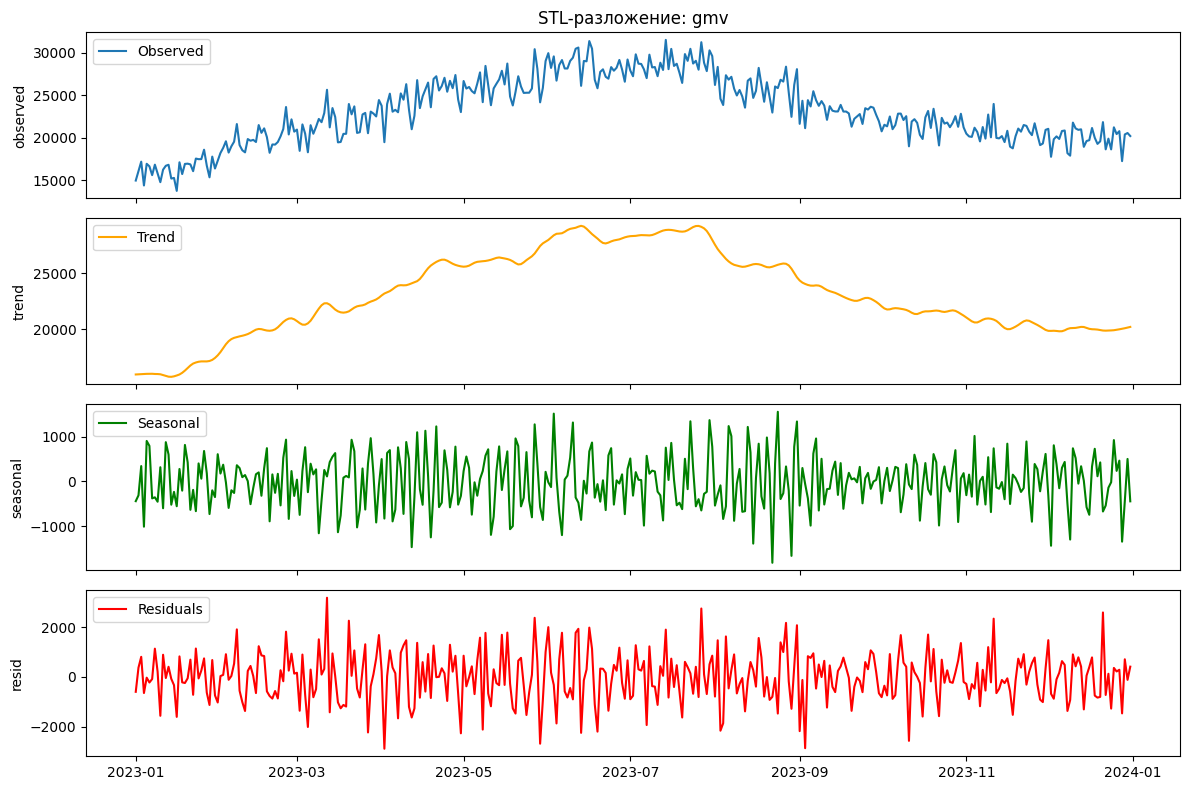

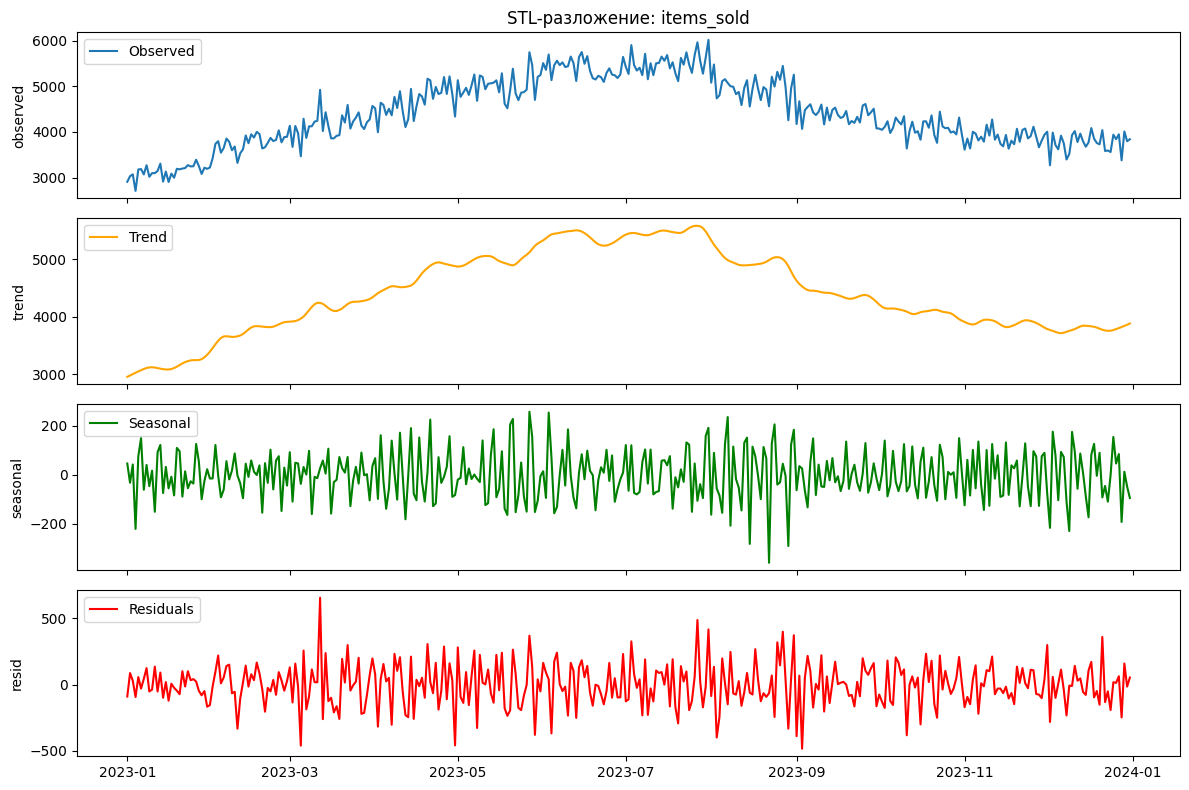

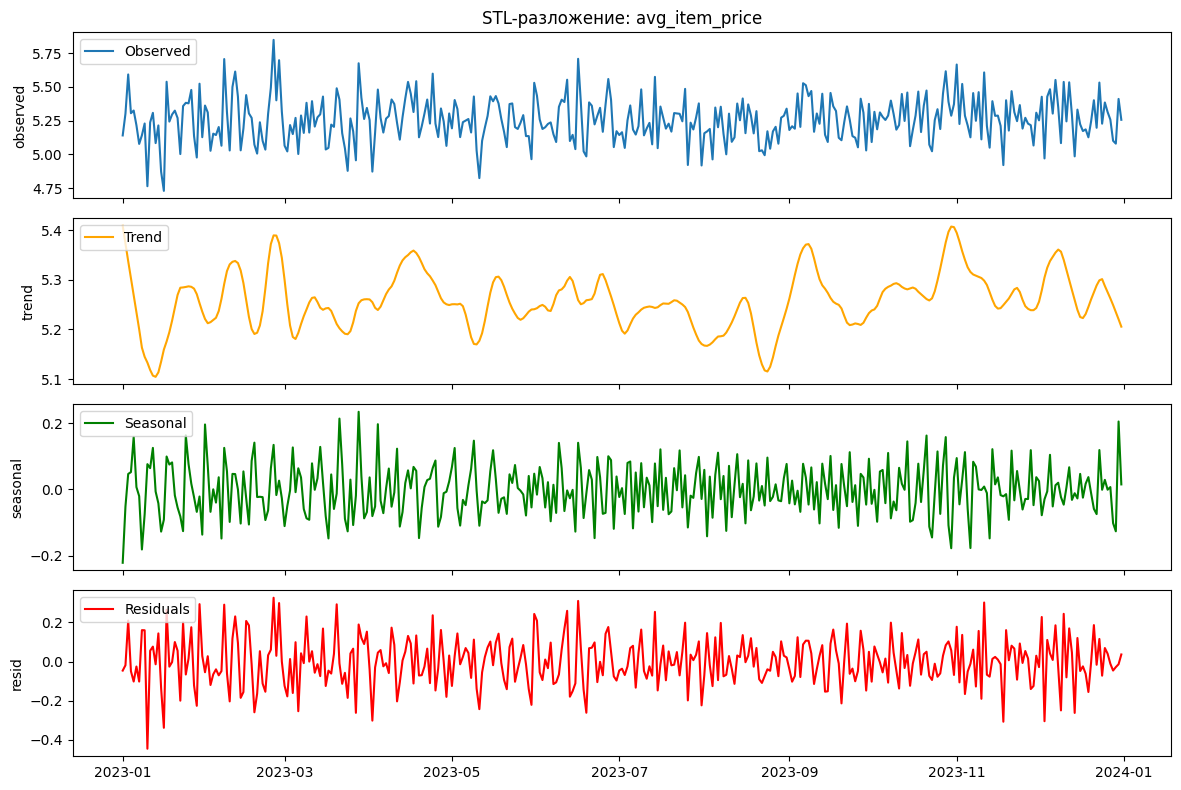

gmv аномалии на остатках STL за май: []
items_sold аномалии на остатках STL за май: []
avg_item_price аномалии на остатках STL за май: []


In [23]:
stl_results = {}

for m in metrics:
    series = df.set_index('date')[m]
    stl = STL(series, period=7).fit()
    stl_results[m] = stl

    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(series.index, series.values)
    axes[0].set_ylabel('observed')
    axes[0].legend(['Observed'], loc='upper left')
    axes[1].plot(series.index, stl.trend, color='orange')
    axes[1].set_ylabel('trend')
    axes[1].legend(['Trend'], loc='upper left')
    axes[2].plot(series.index, stl.seasonal, color='green')
    axes[2].set_ylabel('seasonal')
    axes[2].legend(['Seasonal'], loc='upper left')
    axes[3].plot(series.index, stl.resid, color='red')
    axes[3].set_ylabel('resid')
    axes[3].legend(['Residuals'], loc='upper left')
    axes[0].set_title(f'STL-разложение: {m}')
    plt.tight_layout()
    plt.show()


for m in metrics:
    resid = pd.Series(stl_results[m].resid, index=df['date'])
    x_may = resid.values[may_mask.values]
    dates_may = df.loc[may_mask, 'date'].values
    esd_mask, _ = generalized_esd(x_may, alpha=0.05)
    esd_dates = pd.to_datetime(dates_may[esd_mask]).strftime('%Y-%m-%d').tolist()
    print(m, 'аномалии на остатках STL за май:', esd_dates)

**Вывод по STL:**

* gmv и items_sold хорошо раскладываются: видны тренд и недельная сезонность.
* Для avg_item_price сезонность и тренд выражены слабее, STL для этой метрики менее оправдан — остатки ближе к шуму.

Дополнительно: Generalized ESD на остатках STL не нашёл аномалий за май ни для одной из трёх метрик.

#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

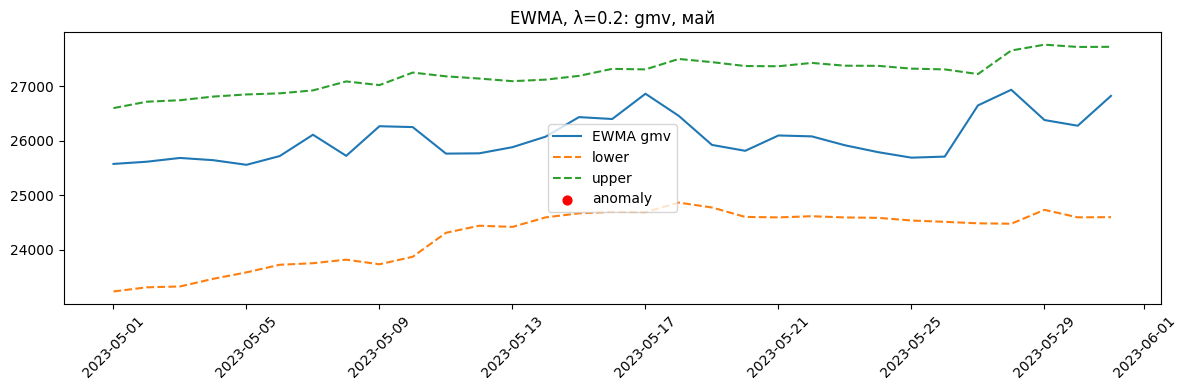

gmv аномалии EWMA за май: []


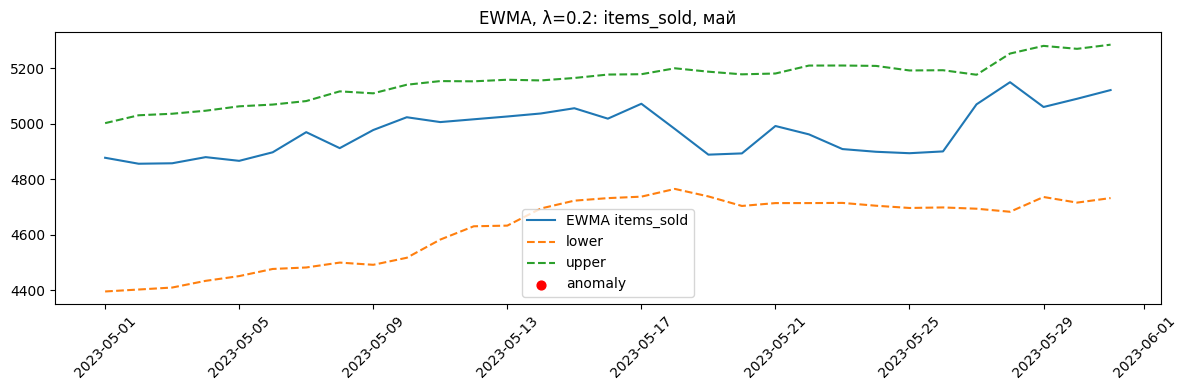

items_sold аномалии EWMA за май: []


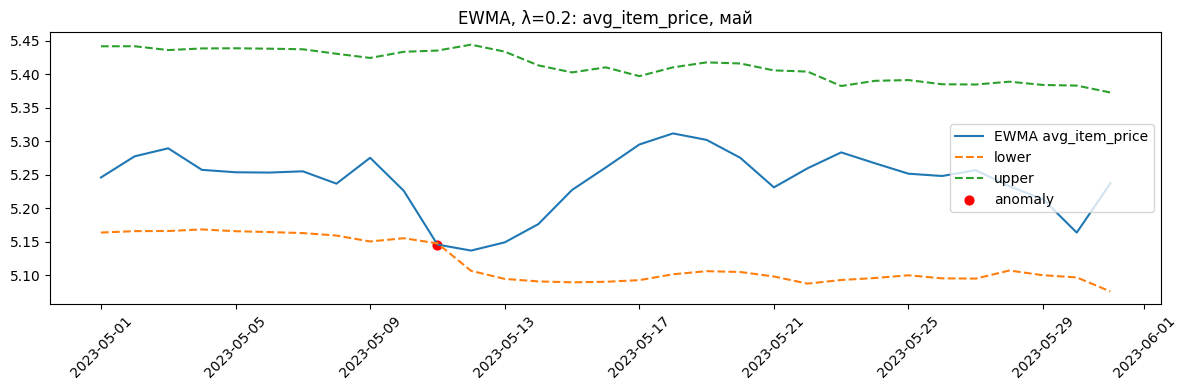

avg_item_price аномалии EWMA за май: ['2023-05-11']


In [24]:
def ewma_anomaly(series, lam=0.2, L=3, window=28):
    s = pd.Series(series).astype(float)
    z = s.ewm(alpha=lam, adjust=False).mean()
    mu = s.rolling(window).mean().shift(1)
    sigma = s.rolling(window).std().shift(1)
    factor = np.sqrt(lam / (2 - lam))
    lower = mu - L * sigma * factor
    upper = mu + L * sigma * factor
    anomaly = (z < lower) | (z > upper)
    return pd.DataFrame({'value': s, 'ewma': z, 'mean': mu, 'std': sigma,
                         'lower': lower, 'upper': upper, 'anomaly': anomaly})


for m in metrics:
    r = ewma_anomaly(df[m])
    plot_df = df.loc[may_mask, ['date']].copy()
    plot_df['ewma'] = r.loc[may_mask, 'ewma'].values
    plot_df['lower'] = r.loc[may_mask, 'lower'].values
    plot_df['upper'] = r.loc[may_mask, 'upper'].values
    plot_df['anomaly'] = r.loc[may_mask, 'anomaly'].values

    plt.figure(figsize=(12, 4))
    plt.plot(plot_df['date'], plot_df['ewma'], label=f'EWMA {m}')
    plt.plot(plot_df['date'], plot_df['lower'], '--', label='lower')
    plt.plot(plot_df['date'], plot_df['upper'], '--', label='upper')
    an = plot_df[plot_df['anomaly']]
    plt.scatter(an['date'], an['ewma'], color='red', s=40, label='anomaly')
    plt.title(f'EWMA, λ=0.2: {m}, май')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(m, 'аномалии EWMA за май:', an['date'].dt.strftime('%Y-%m-%d').tolist())

**Вывод по методам:**  
Для онлайн-мониторинга мне больше нравится EWMA: он рекуррентный, быстро реагирует на сдвиги и не требует хранить всю историю. Для ретроспективного анализа — STL + Generalized ESD или просто Generalized ESD: это батч-подход, который контролирует множественные выбросы и может учитывать сезонность. Правило 3σ на дельтах удобно как простой baseline.